<font size=7 color="#5499C7" >Assignment 4: CNN</font>
- <font size=5>__Group Members__ : Kasra Noorbakhsh - Kourosh Sajjadi </font>
- <font size=5>__Student IDs__  : 810100230 - 810100587</font> 
- <font size=5>__Course__ : Computer Vision</font> 

<font size=7 color="#5499C7">Dataset Loading</font>

In [1]:
from torchvision import datasets, transforms

# Download training and testing data
transform = transforms.Compose([transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))])
train_ds = datasets.FashionMNIST('F_MNIST_data', download=True, train=True, transform=transform)
test_ds = datasets.FashionMNIST('F_MNIST_data', download=True, train=False, transform=transform)

100%|██████████| 26421880/26421880 [04:12<00:00, 104722.86it/s]


Extracting F_MNIST_data\FashionMNIST\raw\train-images-idx3-ubyte.gz to F_MNIST_data\FashionMNIST\raw



100%|██████████| 29515/29515 [00:00<00:00, 9771480.19it/s]


Extracting F_MNIST_data\FashionMNIST\raw\train-labels-idx1-ubyte.gz to F_MNIST_data\FashionMNIST\raw



100%|██████████| 4422102/4422102 [00:46<00:00, 95480.02it/s] 


Extracting F_MNIST_data\FashionMNIST\raw\t10k-images-idx3-ubyte.gz to F_MNIST_data\FashionMNIST\raw



100%|██████████| 5148/5148 [00:00<?, ?it/s]

Extracting F_MNIST_data\FashionMNIST\raw\t10k-labels-idx1-ubyte.gz to F_MNIST_data\FashionMNIST\raw



In [2]:
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

batch_size = 64
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

# Get one batch
images, labels = next(iter(train_loader))

# Print shapes
print(f"Batch of images shape: {images.shape}")  # e.g., torch.Size([64, 1, 28, 28])
print(f"Batch of labels shape: {labels.shape}")  # e.g., torch.Size([64])

Batch of images shape: torch.Size([64, 1, 28, 28])
Batch of labels shape: torch.Size([64])


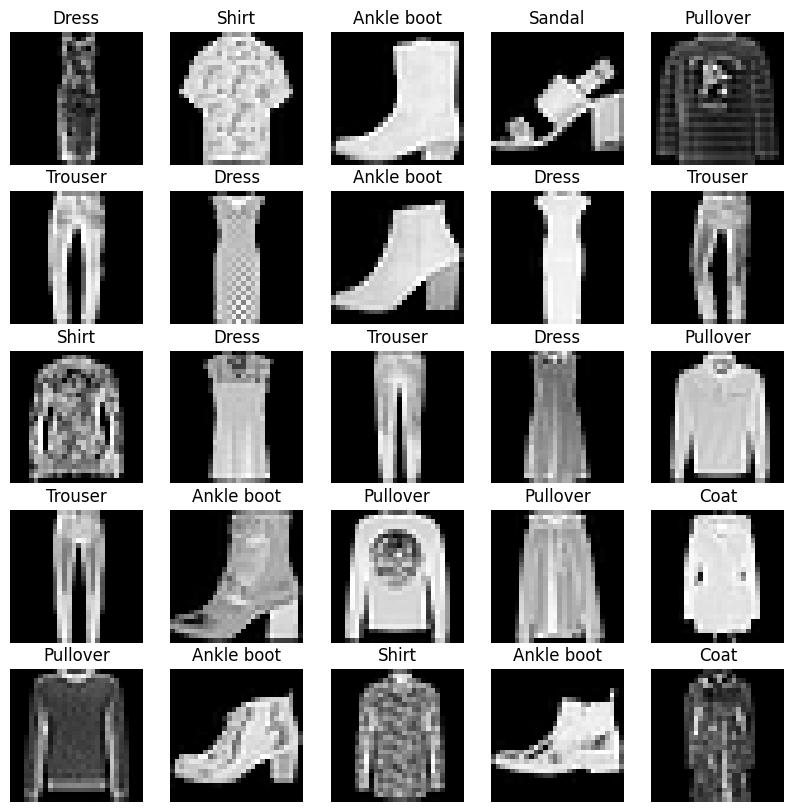

In [3]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

plt.figure(figsize=(10, 10))
for i in range(25):  # Plot first 25 images
    plt.subplot(5, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap='gray')  # Remove channel dim for display
    plt.title(class_names[labels[i]])
    plt.axis('off')
plt.show()

Explanation of Dimensions
Each Fashion-MNIST image has shape (1, 28, 28):

1: Single grayscale channel (unlike RGB images with 3 channels).

28, 28: Height × width in pixels (28×28 grayscale images).

Why flatten?

Fully connected (dense) layers in neural networks expect 1D feature vectors as input. To feed an image into such layers, flatten the spatial dimensions (1, 28, 28) → (784) (28×28=784 features per image), preserving the information while matching the layer's input requirements. (CNNs avoid full flattening by using convolutional layers instead.)

<font size=6 color="#5499C7">o</font>

<font size=5>
T
</font>

<font size=6 color="#5499C7">Per-Image Analysis</font>
<font size=5>

*   **Image 1 (Dog & Bicycle):** This is a multi-object scene. The model successfully identifies both dominant subjects in its top-5 predictions: 
</font>